# 02 — Preprocessing

  # CELLULE 1 — Imports et chargement

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json, joblib, os, warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing   import MinMaxScaler

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize']    = (14, 5)
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
os.makedirs('../models', exist_ok=True)

# Charger le dataset de l'etape 1
df = pd.read_csv('../data/processed/dataset_explore.csv')

# Charger la config
with open('../data/processed/config_etape1.json', 'r') as f:
    config = json.load(f)

CAPTEURS_UTILES   = config['capteurs_utiles']
CAPTEURS_INUTILES = config['capteurs_inutiles']
SEUIL_PANNE       = config['seuil_panne']

print('Dataset charge !')
print(f'  Lignes             : {len(df):,}')
print(f'  Colonnes           : {len(df.columns)}')
print(f'  Capteurs utiles    : {len(CAPTEURS_UTILES)}')
print(f'  Capteurs inutiles  : {len(CAPTEURS_INUTILES)} -> {CAPTEURS_INUTILES}')
print()
df.head(3)


Dataset charge !
  Lignes             : 20,631
  Colonnes           : 28
  Capteurs utiles    : 14
  Capteurs inutiles  : 7 -> ['s19', 's18', 's16', 's10', 's5', 's1', 's6']



,unit_id,cycle,op_set_1,op_set_2,op_set_3,s1,s2,s3,s4,s5,...,s14,s15,s16,s17,s18,s19,s20,s21,RUL,label
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,0


# CELLULE 2 — Supprimer les capteurs inutiles + colonnes op_set

In [2]:

print(f'Avant : {len(df.columns)} colonnes')

#Supprimer les 7 capteurs constants identifies a l'etape 1
df = df.drop(columns=CAPTEURS_INUTILES)

# Supprimer aussi les reglages operationnels (constants dans FD001)
cols_op = [c for c in df.columns if 'op_set' in c]
if cols_op:
    df = df.drop(columns=cols_op)

print(f'Apres  : {len(df.columns)} colonnes')
print(f'Colonnes restantes : {list(df.columns)}')
print(f'NaN total : {df.isnull().sum().sum()}')
df.head(3)

Avant : 28 colonnes
Apres  : 18 colonnes
Colonnes restantes : ['unit_id', 'cycle', 's2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21', 'RUL', 'label']
NaN total : 0


,unit_id,cycle,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,s15,s17,s20,s21,RUL,label
0,1,1,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,191,0
1,1,2,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,190,0
2,1,3,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189,0


# CELLULE 3 — Separer X (features) et y (label)

In [3]:
# Colonnes a exclure des features
COLS_EXCLURE = ['unit_id', 'cycle', 'RUL', 'label']

# X = capteurs uniquement
FEATURE_COLS = [c for c in df.columns if c not in COLS_EXCLURE]

X = df[FEATURE_COLS].copy()
y = df['label'].copy()

print(f'X (features) : {X.shape}  -> {FEATURE_COLS}')
print(f'y (label)    : {y.shape}')
print(f'  Label 0 : {(y==0).sum():,}  ({(y==0).mean()*100:.1f}%)')
print(f'  Label 1 : {(y==1).sum():,}  ({(y==1).mean()*100:.1f}%)')
print()
X.head(3)

X (features) : (20631, 14)  -> ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
y (label)    : (20631,)
  Label 0 : 17,531  (85.0%)
  Label 1 : 3,100  (15.0%)



,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,s15,s17,s20,s21
0,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442


# CELLULE 4 — Division Train / Test : TU CHOISIS LES PARAMETRES

Division : 80% train / 20% test

X_train : (16504, 14)
X_test  : (4127, 14)

Distribution apres division :
  Train -> Label 0 : 14,024 (85.0%)  Label 1 : 2,480 (15.0%)
  Test  -> Label 0 : 3,507  (85.0%)  Label 1 : 620  (15.0%)



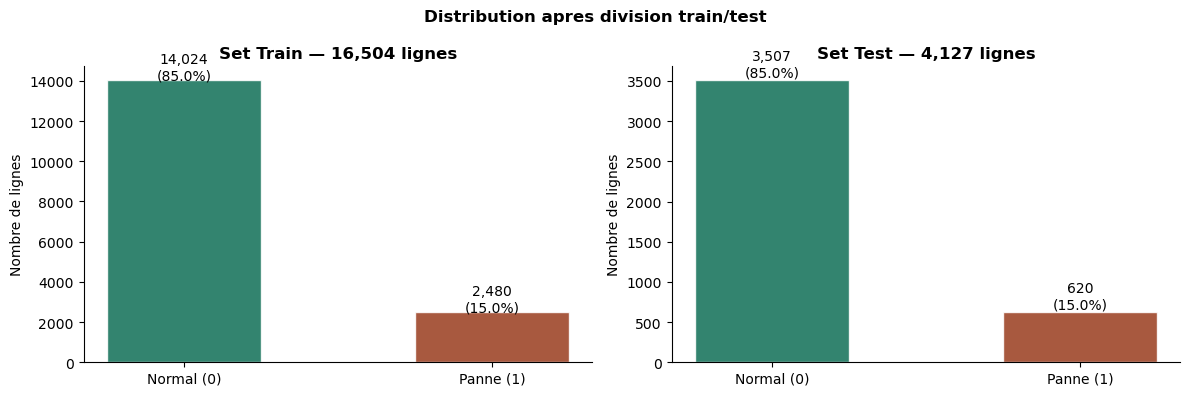

In [4]:
# <- CHANGE CES VALEURS POUR EXPERIMENTER
TEST_SIZE    = 0.20   # 20% pour le test 
RANDOM_STATE = 42     # graine aleatoire 

# Division stratifiee : garde les memes proportions 0/1 dans train et test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size    = TEST_SIZE,
    random_state = RANDOM_STATE,
    stratify     = y
)

print(f'Division : {int((1-TEST_SIZE)*100)}% train / {int(TEST_SIZE*100)}% test')
print()
print(f'X_train : {X_train.shape}')
print(f'X_test  : {X_test.shape}')
print()
print('Distribution apres division :')
print(f'  Train -> Label 0 : {(y_train==0).sum():,} ({(y_train==0).mean()*100:.1f}%)  Label 1 : {(y_train==1).sum():,} ({(y_train==1).mean()*100:.1f}%)')
print(f'  Test  -> Label 0 : {(y_test==0).sum():,}  ({(y_test==0).mean()*100:.1f}%)  Label 1 : {(y_test==1).sum():,}  ({(y_test==1).mean()*100:.1f}%)')
print()

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nom, y_part) in zip(axes, [('Train', y_train), ('Test', y_test)]):
    nb0, nb1 = (y_part==0).sum(), (y_part==1).sum()
    ax.bar(['Normal (0)', 'Panne (1)'], [nb0, nb1],
           color=['#0F6E56', '#993C1D'], alpha=0.85, edgecolor='white', width=0.5)
    ax.set_title(f'Set {nom} — {len(y_part):,} lignes', fontweight='bold')
    ax.set_ylabel('Nombre de lignes')
    for i, v in enumerate([nb0, nb1]):
        ax.text(i, v+50, f'{v:,}\n({v/len(y_part)*100:.1f}%)', ha='center', fontsize=10)
plt.suptitle('Distribution apres division train/test', fontweight='bold')
plt.tight_layout()
plt.savefig('../data/processed/g6_split.png', dpi=150, bbox_inches='tight')
plt.show()

# CELLULE 5 — Normalisation MinMaxScaler
# REGLE : fit sur train UNIQUEMENT, transform sur train + test

In [5]:
scaler = MinMaxScaler()

# FIT uniquement sur train
# Le scaler apprend les min et max de chaque feature
scaler.fit(X_train)

# TRANSFORM train ET test avec les memes parametres
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=FEATURE_COLS)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=FEATURE_COLS)

# Sauvegarder le scaler pour l'API
joblib.dump(scaler, '../models/scaler.pkl')

print('Normalisation terminee !')
print()
print('Avant normalisation (3 premiers capteurs) :')
print(X_train[FEATURE_COLS[:3]].describe().round(2).loc[['min','max']].to_string())
print()
print('Apres normalisation (3 premiers capteurs) :')
print(X_train_scaled[FEATURE_COLS[:3]].describe().round(3).loc[['min','max']].to_string())
print()
print('Les valeurs sont entre 0.0 et 1.0 ok')
print('Scaler sauvegarde : models/scaler.pkl')

Normalisation terminee !

Avant normalisation (3 premiers capteurs) :
         s2       s3       s4
min  641.21  1571.04  1382.25
max  644.53  1616.91  1441.49

Apres normalisation (3 premiers capteurs) :
      s2   s3   s4
min  0.0  0.0  0.0
max  1.0  1.0  1.0

Les valeurs sont entre 0.0 et 1.0 ok
Scaler sauvegarde : models/scaler.pkl


# CELLULE 6 — Visualiser avant / apres normalisation

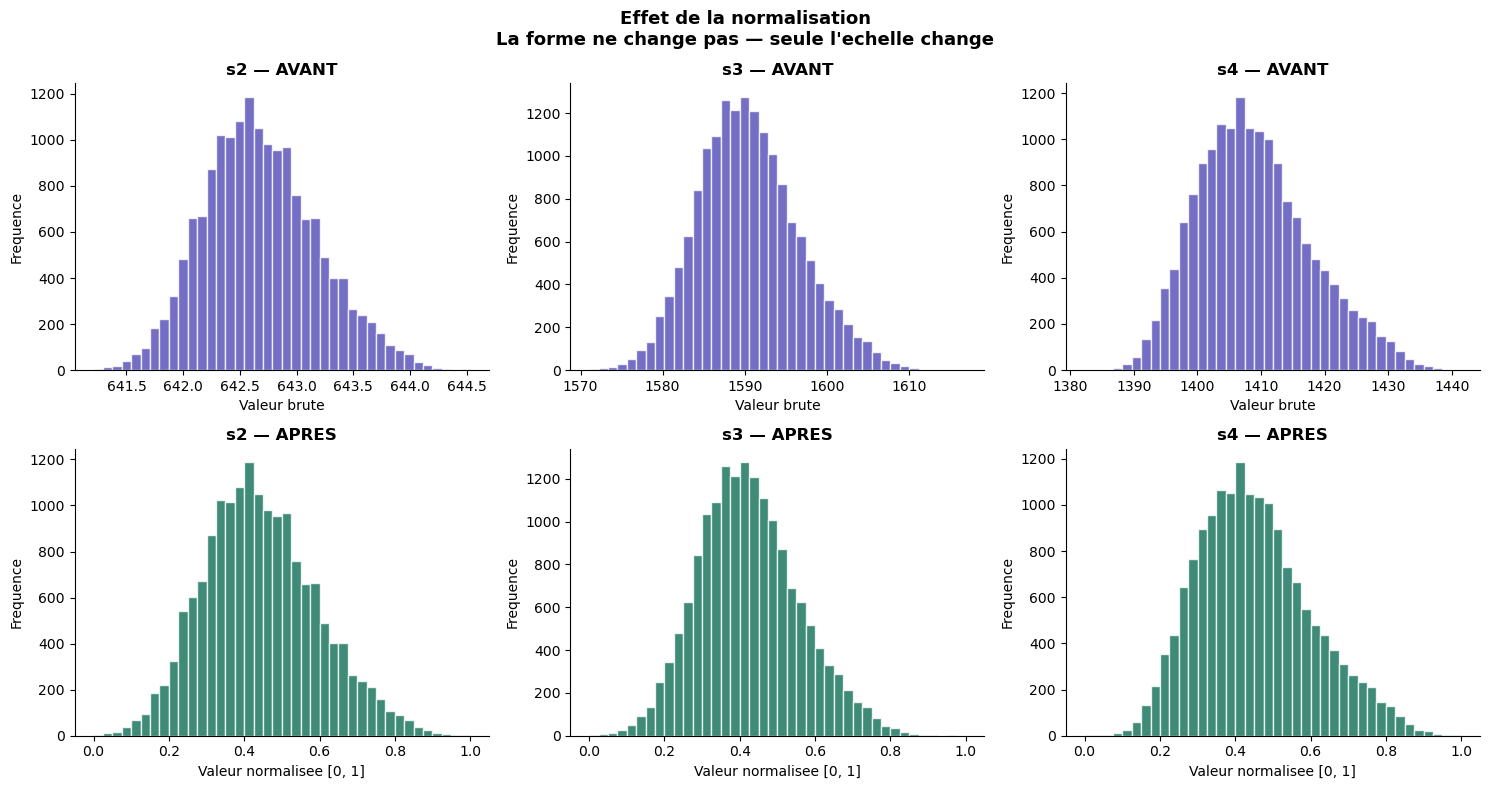

In [6]:
caps_demo = FEATURE_COLS[:3]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, cap in enumerate(caps_demo):
    # Avant
    axes[0, col].hist(X_train[cap], bins=40, color='#534AB7', alpha=0.8, edgecolor='white')
    axes[0, col].set_title(f'{cap} — AVANT', fontweight='bold')
    axes[0, col].set_xlabel(f'Valeur brute')
    axes[0, col].set_ylabel('Frequence')
    # Apres
    axes[1, col].hist(X_train_scaled[cap], bins=40, color='#0F6E56', alpha=0.8, edgecolor='white')
    axes[1, col].set_title(f'{cap} — APRES', fontweight='bold')
    axes[1, col].set_xlabel('Valeur normalisee [0, 1]')
    axes[1, col].set_ylabel('Frequence')

fig.suptitle('Effet de la normalisation\nLa forme ne change pas — seule l\'echelle change',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/processed/g7_normalisation.png', dpi=150, bbox_inches='tight')
plt.show()

# CELLULE 7 — class_weight='balanced'(laisser les donnees reelles, compenser via class_weight dans le modele)

In [7]:
from collections import Counter

print('Distribution des classes (train) :')
print(f'  Label 0 (Normal) : {(y_train==0).sum():,}  ({(y_train==0).mean()*100:.1f}%)')
print(f'  Label 1 (Panne)  : {(y_train==1).sum():,}  ({(y_train==1).mean()*100:.1f}%)')
print()

ratio = (y_train==0).sum() / (y_train==1).sum()
print(f'  Ratio desequilibre : {ratio:.1f}:1  (normal:panne)')
print()
print('Strategie retenue : class_weight="balanced"')
print('  -> Le modele pondere automatiquement les classes selon leur frequence')
print('  -> Aucune donnee synthetique = pas de risque de surapprentissage sur du bruit')
print()
print('Les donnees X_train_scaled et y_train sont utilisees directement.')


Distribution des classes (train) :
  Label 0 (Normal) : 14,024  (85.0%)
  Label 1 (Panne)  : 2,480  (15.0%)

  Ratio desequilibre : 5.7:1  (normal:panne)

Strategie retenue : class_weight="balanced"
  -> Le modele pondere automatiquement les classes selon leur frequence
  -> Aucune donnee synthetique = pas de risque de surapprentissage sur du bruit

Les donnees X_train_scaled et y_train sont utilisees directement.


# CELLULE 8 — Visualiser la distribution train / test (donnees reelles)

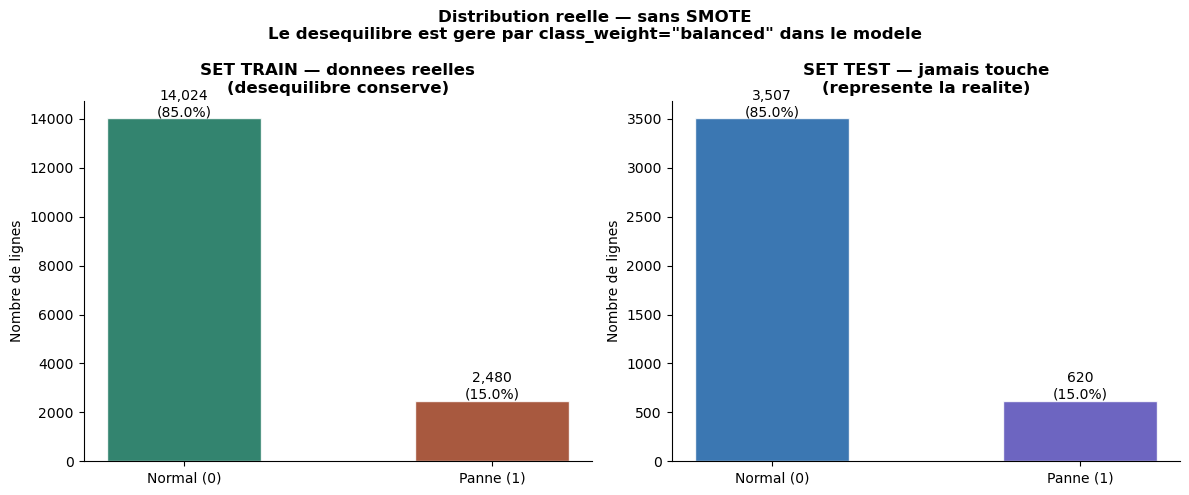

Train et test : donnees 100% reelles, aucune ligne synthetique.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Train
nb0_tr, nb1_tr = (y_train==0).sum(), (y_train==1).sum()
axes[0].bar(['Normal (0)', 'Panne (1)'], [nb0_tr, nb1_tr],
            color=['#0F6E56', '#993C1D'], alpha=0.85, edgecolor='white', width=0.5)
axes[0].set_title('SET TRAIN — donnees reelles\n(desequilibre conserve)', fontweight='bold')
axes[0].set_ylabel('Nombre de lignes')
for i, v in enumerate([nb0_tr, nb1_tr]):
    axes[0].text(i, v + 80, f'{v:,}\n({v/(nb0_tr+nb1_tr)*100:.1f}%)', ha='center', fontsize=10)

# Test
nb0_te, nb1_te = (y_test==0).sum(), (y_test==1).sum()
axes[1].bar(['Normal (0)', 'Panne (1)'], [nb0_te, nb1_te],
            color=['#185FA5', '#534AB7'], alpha=0.85, edgecolor='white', width=0.5)
axes[1].set_title('SET TEST — jamais touche\n(represente la realite)', fontweight='bold')
axes[1].set_ylabel('Nombre de lignes')
for i, v in enumerate([nb0_te, nb1_te]):
    axes[1].text(i, v + 20, f'{v:,}\n({v/(nb0_te+nb1_te)*100:.1f}%)', ha='center', fontsize=10)

plt.suptitle(
    'Distribution reelle — sans SMOTE\n'
    'Le desequilibre est gere par class_weight="balanced" dans le modele',
    fontweight='bold', fontsize=12
)
plt.tight_layout()
plt.savefig('../data/processed/g8_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Train et test : donnees 100% reelles, aucune ligne synthetique.')


# CELLULE 9 — Sauvegarder tous les datasets

In [9]:
# Sauvegarde des donnees reelles (sans SMOTE)
X_train_scaled.to_csv('../data/processed/X_train.csv', index=False)
y_train.to_csv('../data/processed/y_train.csv',        index=False)
X_test_scaled.to_csv('../data/processed/X_test.csv',   index=False)
y_test.to_csv('../data/processed/y_test.csv',          index=False)

# Config pour les prochains notebooks
config2 = {
    'feature_cols'    : FEATURE_COLS,
    'nb_features'     : len(FEATURE_COLS),
    'test_size'       : TEST_SIZE,
    'random_state'    : RANDOM_STATE,
    'smote_applique'  : False,
    'class_weight'    : 'balanced',
    'X_train_shape'   : list(X_train_scaled.shape),
    'X_test_shape'    : list(X_test_scaled.shape),
    'y_train_0'       : int((y_train==0).sum()),
    'y_train_1'       : int((y_train==1).sum()),
    'y_test_0'        : int((y_test==0).sum()),
    'y_test_1'        : int((y_test==1).sum()),
    'scaler_path'     : 'models/scaler.pkl',
}
with open('../data/processed/config_etape2.json', 'w') as f:
    json.dump(config2, f, indent=2)

print('Fichiers sauvegardes :')
for nom in ['X_train.csv', 'y_train.csv', 'X_test.csv', 'y_test.csv']:
    p = f'../data/processed/{nom}'
    taille = os.path.getsize(p) / (1024 * 1024)
    print(f'  {nom:<15} ({taille:.1f} MB)')
print('  config_etape2.json')
print('  models/scaler.pkl')


Fichiers sauvegardes :
  X_train.csv     (4.2 MB)
  y_train.csv     (0.0 MB)
  X_test.csv      (1.0 MB)
  y_test.csv      (0.0 MB)
  config_etape2.json
  models/scaler.pkl


# CELLULE 10 — Resume final

In [10]:
print('=' * 60)
print('   RESUME — ETAPE 2 PREPROCESSING TERMINEE')
print('=' * 60)
print()
print(f'  Capteurs inutiles supprimes : {CAPTEURS_INUTILES}')
print(f'  Features conservees         : {len(FEATURE_COLS)}')
print()
print(f'  Division train/test : {int((1-TEST_SIZE)*100)}% / {int(TEST_SIZE*100)}%')
print(f'  Normalisation       : MinMaxScaler (fit sur train uniquement)')
print(f'  Scaler sauvegarde   : models/scaler.pkl')
print()
print('  Gestion du desequilibre :')
print('    SMOTE         : NON (cause de surapprentissage)')
print('    class_weight  : balanced (configure dans le modele etape 3)')
print(f'    Train -> Label 0 : {(y_train==0).sum():,} normal / Label 1 : {(y_train==1).sum():,} panne')
print(f'    Test  -> Label 0 : {(y_test==0).sum():,} normal  / Label 1 : {(y_test==1).sum():,} panne')
print()
print('  Donnees pretes pour le ML :')
print(f'    X_train : {X_train_scaled.shape}  <- pour entrainer')
print(f'    X_test  : {X_test_scaled.shape}   <- pour evaluer')

   RESUME — ETAPE 2 PREPROCESSING TERMINEE

  Capteurs inutiles supprimes : ['s19', 's18', 's16', 's10', 's5', 's1', 's6']
  Features conservees         : 14

  Division train/test : 80% / 20%
  Normalisation       : MinMaxScaler (fit sur train uniquement)
  Scaler sauvegarde   : models/scaler.pkl

  Gestion du desequilibre :
    SMOTE         : NON (cause de surapprentissage)
    class_weight  : balanced (configure dans le modele etape 3)
    Train -> Label 0 : 14,024 normal / Label 1 : 2,480 panne
    Test  -> Label 0 : 3,507 normal  / Label 1 : 620 panne

  Donnees pretes pour le ML :
    X_train : (16504, 14)  <- pour entrainer
    X_test  : (4127, 14)   <- pour evaluer
